# Decision Trees: intuition, mathematics, and interview depth

A **decision tree** learns a sequence of questions that partitions the feature space into increasingly pure regions. Each internal node asks a question such as `age <= 30`; each branch represents an answer; each leaf stores the prediction. The algorithm is greedy: at every node it chooses the split that gives the largest immediate reduction in impurity.

This notebook uses a tiny classification example so every split can be calculated by hand, then connects the idea to scikit-learn, visualizations, regularization, and common interview questions.

## 1. The core idea

Suppose the target is `Passed` (Yes/No). A tree might learn:

```mermaid
flowchart TD
    A{Study hours <= 3?} -->|Yes| B{Sleep hours <= 5?}
    A -->|No| C[Pass = Yes]
    B -->|Yes| D[Pass = No]
    B -->|No| E[Pass = Yes]
```

A prediction follows exactly one path from root to leaf. In a classification leaf, the usual prediction is the majority class. In a regression leaf, it is usually the mean target value.

**Important mental model:** a tree does not learn a smooth equation. It learns axis-aligned regions and produces a piecewise-constant prediction inside each region.

## 2. How a classification split is scored — derive the math

A tree wants each leaf to be as **pure** as possible. A node containing only `Yes` examples is easy to predict; a node containing half `Yes` and half `No` is uncertain. The split criterion turns that idea into a number.

### Notation: what does every symbol mean?

| Symbol | Meaning |
|---|---|
| $S$ | The set of training rows currently arriving at one node |
| $|S|$ | The number of rows in that node; $|\cdot|$ means set size |
| $K$ | Number of possible classes, e.g. $K=2$ for `Yes`/`No` |
| $k$ | A class index: $1,2,\ldots,K$ |
| $n_k$ | Number of rows in class $k$ inside $S$ |
| $p_k$ | Class probability/proportion: $p_k=n_k/|S|$ |
| $\sum$ | Add the expression for every class; it is shorthand for a loop |
| $\log_2$ | Logarithm base 2; information is measured in bits |
| $S_L,S_R$ | Left and right child subsets after a candidate binary split |
| $|S_L|/|S|$ | Fraction of the parent rows sent to the left child |

The proportions always satisfy:

$$p_1+p_2+\cdots+p_K=\sum_{k=1}^{K}p_k=1$$

### Entropy: measuring uncertainty

First ask: how surprising is one class with probability $p_k$? Information theory defines its self-information as:

$$I(k)=-\log_2(p_k)$$

A rare event has large information: if $p_k=1/8$, then $I(k)=3$ bits. A certain event has no surprise: if $p_k=1$, then $I(k)=0$ bits. The expected surprise over all classes is probability times surprise, added over classes:

$$\begin{aligned}
H(S) &= \sum_{k=1}^{K}p_k I(k)\\
     &= \sum_{k=1}^{K}p_k\left[-\log_2(p_k)\right]\\
     &= -\sum_{k=1}^{K}p_k\log_2(p_k)
\end{aligned}$$

So $H(S)$ is the **average number of bits needed to describe the class**. The minus sign is needed because $0<p_k\le1$ makes $\log_2(p_k)\le0$, while entropy should be non-negative. By convention, the term $0\log_2(0)$ is treated as `0` because its limit is `0`.

For two classes, entropy behaves like this:

| Class proportions | Entropy | Interpretation |
|---|---:|---|
| $(1,0)$ | $0$ | Completely pure; no uncertainty |
| $(0.75,0.25)$ | $0.811$ | Some uncertainty |
| $(0.5,0.5)$ | $1$ | Maximum uncertainty for two classes |

```mermaid
xychart-beta
    title "Binary entropy is highest when classes are balanced"
    x-axis "p(Yes)" [0, 0.25, 0.5, 0.75, 1]
    y-axis "Entropy (bits)" 0 --> 1
    line [0, 0.811, 1, 0.811, 0]
```

### Information gain: compare parent with children

Suppose a candidate question splits $S$ into $S_L$ and $S_R$:

```mermaid
flowchart TD
    P[Parent node] --> L[Left child]
    P --> R[Right child]
```

The expected uncertainty after asking the question is a **weighted average**. A child containing 90% of the rows must count more than a child containing 10%:

$$H_{children}=\frac{|S_L|}{|S|}H(S_L)+\frac{|S_R|}{|S|}H(S_R)$$

Therefore the information gained by the question is the uncertainty removed:

$$\begin{aligned}
IG(S,\text{split}) &= H(S)-H_{children}\\
 &=H(S)-\frac{|S_L|}{|S|}H(S_L)-\frac{|S_R|}{|S|}H(S_R)
\end{aligned}$$

The algorithm tests possible features and thresholds, then chooses the split with the **largest $IG$**. Equivalently, it chooses the split with the smallest weighted child entropy.

#### Worked calculation

Take a parent with 8 rows: 4 `No` and 4 `Yes`. Its probabilities are $(0.5,0.5)$, so:

$$H(S)=-0.5\log_2(0.5)-0.5\log_2(0.5)=1$$

A candidate split creates a left child of 4 rows `(3 No, 1 Yes)` and a right child of 4 rows `(1 No, 3 Yes)`. Each child has probabilities $(0.75,0.25)$:

$$H(S_L)=H(S_R)=-0.75\log_2(0.75)-0.25\log_2(0.25)\approx0.811$$

Because both children contain $4/8=0.5$ of the data:

$$H_{children}=0.5(0.811)+0.5(0.811)=0.811$$
$$IG=1-0.811=0.189\text{ bits}$$

A perfect split would create pure children, $H(S_L)=H(S_R)=0$, and therefore $IG=1-0=1$ bit. This is why the tree prefers pure children.

### Gini impurity: an alternative derivation

Imagine choosing a row at random and predicting its class using the node's class proportions. The probability of being correct is $\sum_k p_k^2$: we choose class $k$ with probability $p_k$, and the row is actually class $k$ with probability $p_k$. Therefore the probability of being wrong is:

$$Gini(S)=1-\sum_{k=1}^{K}p_k^2$$

For binary classes, $Gini=p(1-p)+(1-p)p=2p(1-p)$. It is `0` for a pure node and `0.5` at $p=0.5$. Unlike entropy, a Gini-based tree chooses the split that **minimizes weighted child Gini**. Both criteria usually rank useful splits similarly.

### Regression trees: why MSE and the mean appear

For numeric targets, a leaf predicts one constant $c$. The squared-error cost inside node $S$ is:

$$\text{SSE}(c)=\sum_{i\in S}(y_i-c)^2$$

To find the best constant, differentiate and set the derivative to zero:

$$\frac{d}{dc}\sum_{i\in S}(y_i-c)^2=-2\sum_{i\in S}(y_i-c)=0$$
$$|S|c=\sum_{i\in S}y_i\quad\Rightarrow\quad c=\bar y_S=\frac{1}{|S|}\sum_{i\in S}y_i$$

That is why the regression leaf prediction is the mean. The node's mean squared error is:

$$MSE(S)=\frac{1}{|S|}\sum_{i\in S}(y_i-\bar y_S)^2$$

The regression split is selected by minimizing weighted child MSE (or, equivalently, maximizing the reduction from the parent MSE).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(42)

In [2]:
def entropy(labels):
    """Shannon entropy of a one-dimensional class-label array."""
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / counts.sum()
    return float(-(probabilities * np.log2(probabilities)).sum())


def gini(labels):
    """Gini impurity of a one-dimensional class-label array."""
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / counts.sum()
    return float(1 - (probabilities ** 2).sum())


def information_gain(parent, left, right):
    weighted_children = (len(left) * entropy(left) + len(right) * entropy(right)) / len(parent)
    return entropy(parent) - weighted_children


parent = np.array(["No"] * 4 + ["Yes"] * 4)
left = np.array(["No"] * 3 + ["Yes"] * 1)
right = np.array(["No"] * 1 + ["Yes"] * 3)

print(f"Parent entropy: {entropy(parent):.3f}")
print(f"Left entropy:   {entropy(left):.3f}")
print(f"Right entropy:  {entropy(right):.3f}")
print(f"Information gain: {information_gain(parent, left, right):.3f}")
print(f"Parent Gini: {gini(parent):.3f}; left/right Gini: {gini(left):.3f}/{gini(right):.3f}")

Parent entropy: 1.000
Left entropy:   0.811
Right entropy:  0.811
Information gain: 0.189
Parent Gini: 0.500; left/right Gini: 0.375/0.375


For the worked split, the parent is balanced, so $H(parent)=1$. Each child has proportions $3/4$ and $1/4$, giving entropy about `0.811`. The weighted child entropy is also `0.811`, so the information gain is about `0.189`. A split with pure children would have gain `1.0` here and would be preferred.

**How thresholds are searched:** for a numeric feature, sort its unique values and test thresholds between adjacent values (often their midpoints). For each candidate, compute the weighted impurity; choose the best one. This search is why trees can model nonlinear relationships without feature scaling.

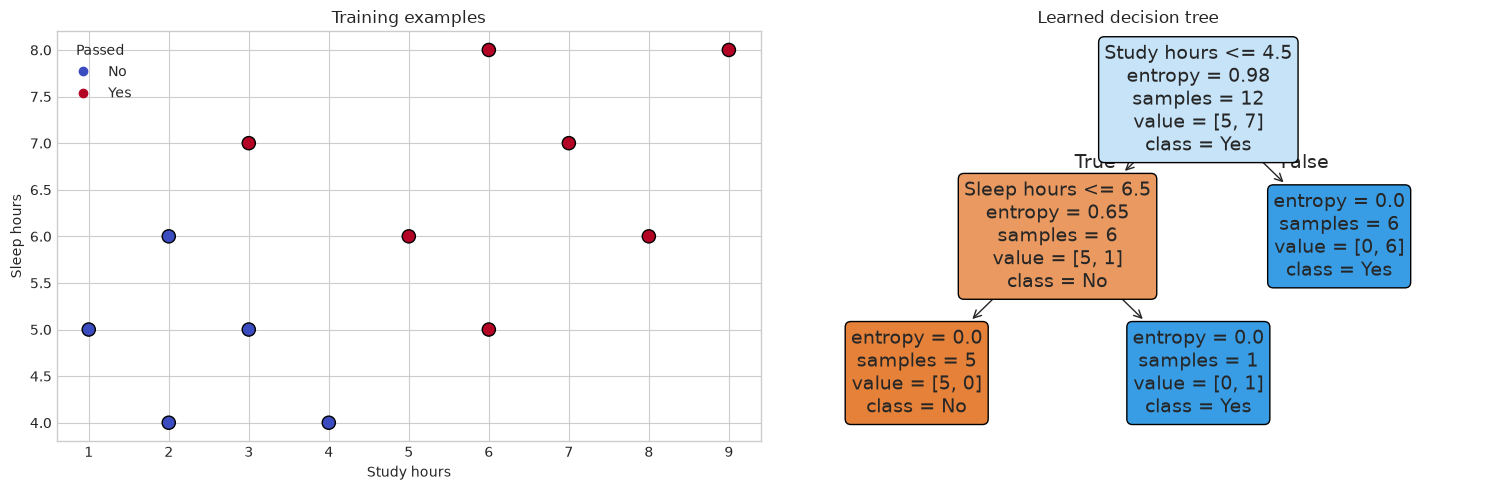

In [3]:
# A small, interpretable dataset: study hours and sleep hours predict passing.
X = pd.DataFrame({
    "Study hours": [1, 2, 2, 3, 3, 4, 5, 6, 6, 7, 8, 9],
    "Sleep hours": [5, 6, 4, 5, 7, 4, 6, 5, 8, 7, 6, 8],
})
y = np.array(["No", "No", "No", "No", "Yes", "No", "Yes", "Yes", "Yes", "Yes", "Yes", "Yes"])

clf = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42)
clf.fit(X, y)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
scatter = axes[0].scatter(X["Study hours"], X["Sleep hours"], c=(y == "Yes"), cmap="coolwarm", s=90, edgecolor="black")
axes[0].set(title="Training examples", xlabel="Study hours", ylabel="Sleep hours")
handles, _ = scatter.legend_elements()
axes[0].legend(handles, ["No", "Yes"], title="Passed")
plot_tree(clf, feature_names=X.columns, class_names=clf.classes_, filled=True, rounded=True, ax=axes[1])
axes[1].set_title("Learned decision tree")
plt.tight_layout()
plt.show()

### Reading a scikit-learn node

- **`samples`**: number of training rows reaching that node.
- **`value`**: class counts at the node (the order is given by `class_names`).
- **`gini` / `entropy`**: impurity before the next split.
- **`class`**: the majority-class prediction for that node.
- Color intensity indicates purity: darker means more concentrated in one class.

A tree can perfectly memorize training data if allowed to grow indefinitely. That is low bias but high variance: small changes in data can produce a very different tree.

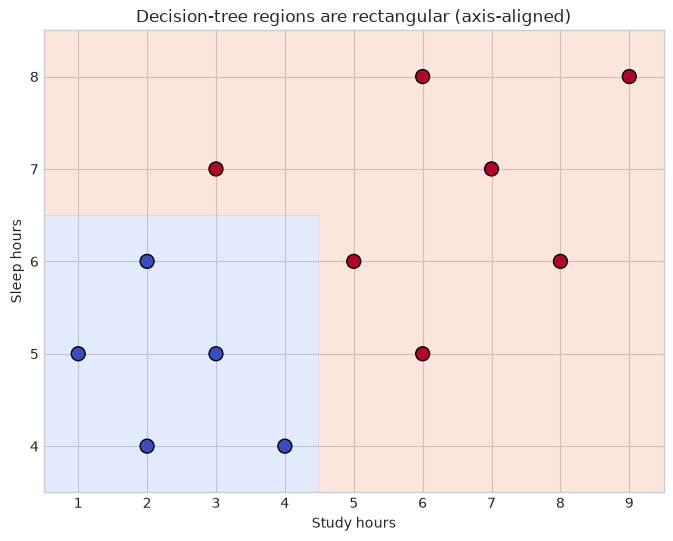

In [4]:
# Visualize the piecewise-constant decision regions.
x_min, x_max = X["Study hours"].min() - .5, X["Study hours"].max() + .5
y_min, y_max = X["Sleep hours"].min() - .5, X["Sleep hours"].max() + .5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = pd.DataFrame({"Study hours": xx.ravel(), "Sleep hours": yy.ravel()})
region = clf.predict(grid).reshape(xx.shape) == "Yes"

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, region, alpha=.25, cmap="coolwarm")
plt.scatter(X["Study hours"], X["Sleep hours"], c=(y == "Yes"), cmap="coolwarm", s=100, edgecolor="black")
plt.xlabel("Study hours")
plt.ylabel("Sleep hours")
plt.title("Decision-tree regions are rectangular (axis-aligned)")
plt.show()

## 3. Material from the Session 8 DT PDF: ID3, CART, and a complete example

The course material presents two classic tree algorithms:

| Algorithm | Main split criterion | Typical use |
|---|---|---|
| **ID3** | Entropy and information gain | Categorical classification; choose the attribute with the largest gain |
| **CART** | Gini impurity for classification, squared error for regression | Binary splits; the common foundation of many practical implementations |

### The ID3 law: choose the largest information gain

For every candidate attribute $A$, ID3 computes its expected entropy after the split:

$$I(S,A)=\sum_{v\in Values(A)}\frac{|S_v|}{|S|}H(S_v)$$

Here, $A$ is an attribute, $v$ is one of its possible values, and $S_v$ is the subset whose attribute value is $v$. The information gain law is:

$$Gain(S,A)=H(S)-I(S,A)$$

Choose $A^*=\arg\max_A Gain(S,A)$. In words: **select the attribute that leaves the least weighted uncertainty, or equivalently removes the most uncertainty**. Then repeat the same calculation independently inside every non-pure child node.

### ID3 workflow from the material

```mermaid
flowchart TD
    A[Start with training set] --> B[Calculate parent entropy]
    B --> C[Calculate weighted child entropy for every attribute]
    C --> D[Compute gain = parent entropy - child entropy]
    D --> E[Choose attribute with highest gain]
    E --> F{Are all child nodes pure?}
    F --> G[Create class-prediction leaves]
    F --> C[Split non-pure nodes again]
```

### Complete worked example: the 14-row Play Tennis dataset

The dataset in the PDF contains four input attributes and a binary target:

| Day | Outlook | Temperature | Humidity | Windy | Play Tennis |
|---:|---|---|---|---|---|
| 1 | Sunny | Hot | High | Weak | No |
| 2 | Sunny | Hot | High | Strong | No |
| 3 | Overcast | Hot | High | Weak | Yes |
| 4 | Rain | Mild | High | Weak | Yes |
| 5 | Rain | Cool | Normal | Weak | Yes |
| 6 | Rain | Cool | Normal | Strong | No |
| 7 | Overcast | Cool | Normal | Strong | Yes |
| 8 | Sunny | Mild | High | Weak | No |
| 9 | Sunny | Cool | Normal | Weak | Yes |
| 10 | Rain | Mild | Normal | Weak | Yes |
| 11 | Sunny | Mild | Normal | Strong | Yes |
| 12 | Overcast | Mild | High | Strong | Yes |
| 13 | Overcast | Hot | Normal | Weak | Yes |
| 14 | Rain | Mild | High | Strong | No |

There are 9 `Yes` rows and 5 `No` rows. The root entropy is:

$$H(S)=-\frac{9}{14}\log_2\left(\frac{9}{14}\right)-\frac{5}{14}\log_2\left(\frac{5}{14}\right)\approx0.940$$

#### Step 1: calculate every candidate root split

For each attribute value, count `Yes` and `No`, calculate that group's entropy, then weight it by the group's size. For `Outlook`:

- `Sunny`: 5 rows = 2 Yes, 3 No, so $H(Sunny)=-\frac25\log_2\frac25-\frac35\log_2\frac35\approx0.971$.
- `Overcast`: 4 rows = 4 Yes, 0 No, so $H(Overcast)=0$ because it is pure.
- `Rain`: 5 rows = 3 Yes, 2 No, so $H(Rain)\approx0.971$.

$$I(S,Outlook)=\frac5{14}(0.971)+\frac4{14}(0)+\frac5{14}(0.971)\approx0.693$$
$$Gain(S,Outlook)=0.940-0.693=0.247$$

The same calculation for every candidate gives:

| Attribute | Value counts `(Yes, No)` | Weighted entropy $I(S,A)$ | Gain $H(S)-I(S,A)$ |
|---|---|---:|---:|
| `Outlook` | Sunny `(2,3)`, Overcast `(4,0)`, Rain `(3,2)` | 0.693 | **0.247** |
| `Temperature` | Hot `(2,2)`, Mild `(4,2)`, Cool `(3,1)` | 0.911 | 0.029 |
| `Humidity` | High `(3,4)`, Normal `(6,1)` | 0.788 | 0.152 |
| `Windy` | Weak `(6,2)`, Strong `(3,3)` | 0.892 | 0.048 |

For example:

$$I(S,Temperature)=\frac4{14}(1.000)+\frac6{14}(0.918)+\frac4{14}(0.811)\approx0.911$$
$$Gain(S,Temperature)=0.940-0.911=0.029$$

Since `Outlook` has the largest gain (`0.247`), ID3 selects it as the root.

#### Step 2: recursively solve each non-pure branch

**Overcast branch:** all four examples are `Yes`, so its entropy is `0`; stop and create the leaf `Yes`.

**Sunny branch:** there are 5 rows (2 Yes, 3 No), so $H(Sunny)=0.971$. `Humidity` separates them perfectly: High has 0 Yes and 3 No, while Normal has 2 Yes and 0 No.

$$I(Sunny,Humidity)=\frac35(0)+\frac25(0)=0$$
$$Gain(Sunny,Humidity)=0.971-0=0.971$$

Thus Sunny becomes `Humidity`: High -> `No`, Normal -> `Yes`.

**Rain branch:** there are 5 rows (3 Yes, 2 No), so $H(Rain)=0.971$. `Windy` separates them perfectly: Weak has 3 Yes and 0 No, while Strong has 0 Yes and 2 No.

$$I(Rain,Windy)=\frac35(0)+\frac25(0)=0$$
$$Gain(Rain,Windy)=0.971-0=0.971$$

Thus Rain becomes `Windy`: Weak -> `Yes`, Strong -> `No`. The final tree is:

```mermaid
flowchart TD
    A[Outlook] --> B[Sunny]
    A --> C[Overcast: Yes]
    A --> D[Rainy]
    B --> E[Humidity]
    E --> F[High: No]
    E --> G[Normal: Yes]
    D --> H[Windy]
    H --> I[Strong: No]
    H --> J[Weak: Yes]
```

### Recap from the course note

![Decision tree recap: strengths and limitations](../Material/dt-recap.png)

**Strengths:** easy to explain, interpretable, naturally handles categorical variables, and fast at prediction. **Limitations:** high variance, poor at representing additive relationships, and often lower predictive accuracy than ensembles unless carefully regularized.

This example demonstrates the central rule: **a tree is built recursively, but every split is chosen greedily using the best local impurity reduction**. It also explains why the final tree can be different when using CART/Gini instead of ID3/entropy: the criterion and allowed split structure are different.

Source: `src/ML/Session-8/Material/DT.pdf` (course slides, pages 10–43).

## 3. Regularization and generalization

The most important tree hyperparameters are:

- `max_depth`: maximum number of levels; lower values reduce variance.
- `min_samples_split`: minimum rows required to split a node.
- `min_samples_leaf` (**minimum leaf size**): minimum rows allowed in every leaf; prevents tiny, memorizing leaves.
- `max_leaf_nodes` (**maximum number of nodes/leaves**): direct cap on model complexity and tree size.
- `min_impurity_decrease` (**minimum decrease in loss**): split only when the weighted impurity reduction reaches this threshold.
- `max_features`: restricts features considered at each split (especially useful in forests).
- `criterion`: `gini`, `entropy`, or `log_loss` for classification; `squared_error` and alternatives for regression.

The four regularization techniques highlighted in the course note are therefore:

1. **Minimum leaf size:** force each final region to contain enough observations.
2. **Maximum depth:** stop recursive splitting after a fixed number of levels.
3. **Maximum number of nodes/leaves:** limit the total size of the tree.
4. **Minimum decrease in loss:** reject a split whose impurity reduction is too small to justify its complexity.

For a classification split, if $I(S)$ is the parent impurity and $I(S_L),I(S_R)$ are child impurities, the weighted reduction is:

$$\Delta I=I(S)-\frac{|S_L|}{|S|}I(S_L)-\frac{|S_R|}{|S|}I(S_R)$$

With `min_impurity_decrease = d`, the split is accepted only when $\Delta I\ge d$ (the exact implementation also accounts for the weighted sample count). A larger threshold creates a smaller, more conservative tree; `0` allows every split that improves the criterion.

Use a validation set or cross-validation to select these values. Do not tune on the test set. Pruning is another strategy: **pre-pruning** stops growth early; **post-pruning** first grows a tree and then removes branches whose complexity is not justified by validation performance. In scikit-learn, cost-complexity pruning uses:

$$R_\alpha(T)=R(T)+\alpha|T|$$

where $R(T)$ is the tree error, $|T|$ is the number of leaves, and $\alpha$ controls the penalty for complexity (`ccp_alpha`).

## 4. Ensembling: combining many models

An **ensemble** combines several models instead of trusting one model. The central idea is that different models make different mistakes. If their errors are not perfectly correlated, combining them can improve generalization.

This is especially useful for decision trees: a deep tree has low bias but high variance, so ensembles can keep much of its flexibility while reducing sensitivity to the particular training sample.

```mermaid
flowchart LR
    D[Training data] --> T1[Model 1]
    D --> T2[Model 2]
    D --> T3[Model 3]
    T1 --> C[Combine predictions]
    T2 --> C
    T3 --> C
    C --> P[Final prediction]
```

### Why averaging reduces variance

For $M$ regression models with predictions $f_1(x),\ldots,f_M(x)$, an average ensemble predicts:

$$\hat f_{ens}(x)=\frac1M\sum_{m=1}^{M}f_m(x)$$

If every model has variance $\sigma^2$ and pairwise error correlation $\rho$, the approximate ensemble variance is:

$$Var(\hat f_{ens})=\sigma^2\left(\rho+\frac{1-\rho}{M}\right)$$

As $M$ increases, the independent part of the noise shrinks. The correlation term $\rho\sigma^2$ does not disappear, which is why **diversity matters**: identical trees add computation but little new information.

For classification, hard voting chooses the most common class:

$$\hat y=\operatorname{mode}(f_1(x),\ldots,f_M(x))$$

Soft voting instead averages class probabilities and chooses the largest average probability.

### 1. Bagging (Bootstrap Aggregating)

Bagging creates $M$ bootstrap datasets by sampling rows **with replacement**, fits one model on each sample, and aggregates the predictions. Each bootstrap sample has roughly 63.2% unique training rows on average; the remaining rows are out-of-bag for that model and can estimate validation performance.

```mermaid
flowchart TD
    D[Original data] --> B1[Bootstrap sample 1]
    D --> B2[Bootstrap sample 2]
    D --> B3[Bootstrap sample M]
    B1 --> T1[Deep tree 1]
    B2 --> T2[Deep tree 2]
    B3 --> T3[Deep tree M]
    T1 --> V[Vote or average]
    T2 --> V
    T3 --> V
```

Bagging mainly reduces **variance**. It does not deliberately reduce correlation between trees as strongly as a random forest does.

### 2. Random Forest

A random forest adds feature randomness to bagging. At each split, a tree considers only a random subset of features. This makes trees less similar, decreases error correlation, and usually improves the variance reduction.

**Random forest recipe:** bootstrap rows -> grow many trees -> randomly restrict features at each split -> vote or average predictions.

Important hyperparameters are `n_estimators`, `max_features`, `max_depth`, `min_samples_leaf`, and `bootstrap`. More trees generally stabilize the result, but cannot fix a systematically biased feature representation.

### 3. Boosting

Boosting builds models **sequentially**, where later weak learners focus on mistakes made by earlier learners. Instead of averaging independent high-variance trees, boosting usually uses shallow trees to build a strong, lower-bias model.

For gradient boosting regression, begin with a constant prediction $F_0(x)$ and repeatedly fit a tree to the negative gradient (for squared error, this is the residual):

$$r_{im}=-\left[\frac{\partial L(y_i,F(x_i))}{\partial F(x_i)}\right]_{F=F_{m-1}}$$
$$F_m(x)=F_{m-1}(x)+\eta\,\gamma_m h_m(x)$$

Here, $h_m$ is the new tree, $\gamma_m$ is its fitted step size, and $\eta$ is the learning rate. A smaller $\eta$ usually requires more trees but can generalize better.

Common boosting families are **AdaBoost**, **Gradient Boosting**, **XGBoost**, **LightGBM**, and **CatBoost**. XGBoost/LightGBM/CatBoost add engineering and regularization improvements such as efficient split search, shrinkage, subsampling, and explicit penalties.

### 4. Voting and weighted voting

Voting combines different model types, such as a tree, logistic regression, and SVM:

$$\hat y=\operatorname{mode}(f_1(x),f_2(x),\ldots,f_M(x))$$

Weighted soft voting uses validation-selected weights $w_m\ge0$ with $\sum_m w_m=1$:

$$\hat p(y=k|x)=\sum_{m=1}^{M}w_m p_m(y=k|x)$$

Use a validation set or cross-validation to choose weights; do not choose them using the test set.

### 5. Stacking and blending

Stacking trains a **meta-model** on the predictions of base models. To avoid leakage, the meta-model must receive out-of-fold predictions: each training row's base prediction is generated by a model that did not train on that row.

Blending is a simpler version: train base models, predict on one held-out validation set, and train the meta-model on those validation predictions. Stacking uses cross-validation more efficiently; blending is simpler but sacrifices some training data.

### Interview comparison

| Technique | Main idea | Main effect | Typical risk |
|---|---|---|---|
| Bagging | Bootstrap rows and average | Reduces variance | Trees may remain correlated |
| Random forest | Bagging + random feature subsets | Reduces variance and correlation | Less interpretable than one tree |
| Boosting | Sequentially correct errors | Reduces bias and builds accuracy | Sensitive to noise and tuning |
| Voting | Combine different model predictions | Stabilizes decisions | Poor probabilities can hurt soft voting |
| Stacking | Learn how to combine base predictions | Exploits complementary models | Leakage if out-of-fold predictions are not used |
| Blending | Meta-model on held-out predictions | Simple model combination | Uses less data for base training |

**Rule of thumb:** choose random forests when you want a strong, robust tree ensemble with limited tuning; choose boosting when maximum tabular accuracy is the priority and you can tune carefully; choose stacking when genuinely different models make complementary errors.

## 5. Interview checklist: answers worth remembering

1. **Why do trees usually not need feature scaling?** They compare one feature to a threshold, so a monotonic rescaling changes the threshold but not the ordering. Scaling is still relevant for pipelines containing other models.
2. **Why are trees high variance?** Greedy early splits affect every descendant; a small data change can change the root split and the whole structure.
3. **What is the bias-variance trade-off?** A shallow tree underfits (high bias); a deep tree overfits (high variance). Depth, leaf size, and pruning control this.
4. **How do trees handle missing values and categories?** The exact behavior is library-dependent. One-hot encoding plus imputation is a common portable pipeline; native categorical/missing-value support must be checked for the chosen implementation.
5. **Are trees interpretable?** Individual paths are easy to explain, but a large tree is not automatically interpretable. Feature importance can be misleading when features are correlated; permutation importance or SHAP can provide better diagnostics.
6. **What is a limitation of greedy splitting?** The best local split does not guarantee the globally optimal tree. Finding the globally optimal binary tree is computationally difficult, so practical algorithms use greedy heuristics.
7. **Decision tree vs random forest?** A random forest averages many decorrelated trees, reducing variance and usually improving accuracy, at the cost of some interpretability and more computation.
8. **Why can impurity-based importance be biased?** Features with many possible thresholds (continuous or high-cardinality categorical features) have more chances to create an apparently good split. Validate importance with permutation tests and domain knowledge.

### Final summary

A decision tree repeatedly chooses the feature and threshold that most reduces weighted impurity, recursively partitions the data, and predicts from the leaf. The mathematics explains the split criterion; the visualizations explain the resulting rectangular regions; regularization explains whether the learned structure generalizes; ensembling combines many trees or model types to improve robustness and accuracy.